<h2>Dataset Loading</h2>

In [2]:
!pip install kagglehub


   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   -------------------- ------------------- 1/2 [kagglehub]
   ---------------------------------------- 2/2 [kagglehub]




[notice] A new release of pip is available: 25.3 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


100%|██████████| 142M/142M [00:10<00:00, 13.9MB/s] 

Extracting files...


Dataset Path: C:\Users\mails\.cache\kagglehub\datasets\angelolmg\tilda-400-64x64-patches\versions\1


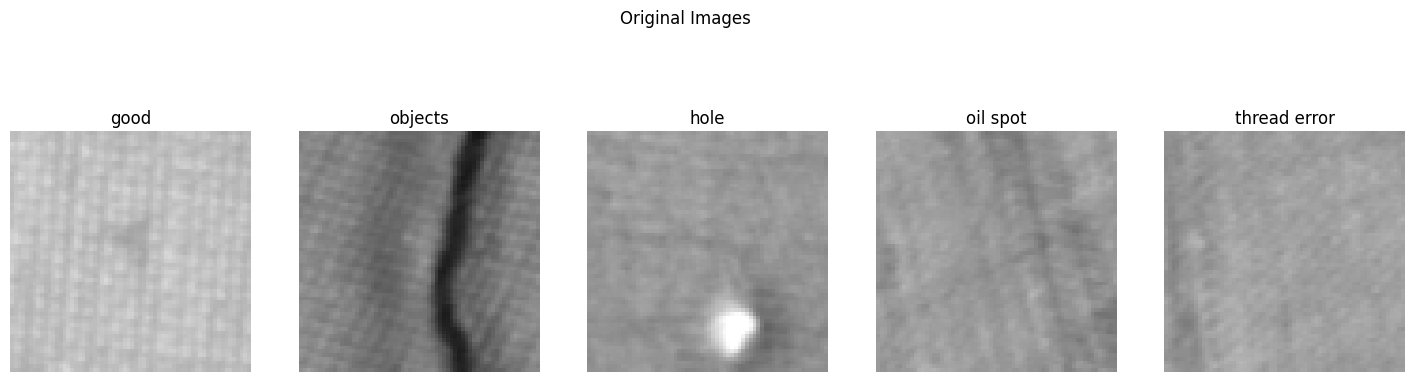

In [3]:
import os
import glob
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import kagglehub

random.seed(42)

# Download dataset
dataset_path = kagglehub.dataset_download("angelolmg/tilda-400-64x64-patches")
print("Dataset Path:", dataset_path)

# Dataset folders
image_folders = [
    os.path.join(dataset_path, "good"),
    os.path.join(dataset_path, "objects"),
    os.path.join(dataset_path, "hole"),
    os.path.join(dataset_path, "oil spot"),
    os.path.join(dataset_path, "thread error")
]

# Pick one random image from each folder
images = {}
titles = []

for folder in image_folders:

    files = glob.glob(os.path.join(folder, "*.png"))

    if len(files) == 0:
        files = glob.glob(os.path.join(folder, "*.jpg"))

    img_path = random.choice(files)

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    folder_name = os.path.basename(folder)

    images[folder_name] = img
    titles.append(folder_name)

# Display originals
fig, ax = plt.subplots(1, len(images), figsize=(18,5))

for i,(name,img) in enumerate(images.items()):
    ax[i].imshow(img)
    ax[i].set_title(name)
    ax[i].axis("off")

plt.suptitle("Original Images")
plt.show()

<h2>Image Interpolation</h2>

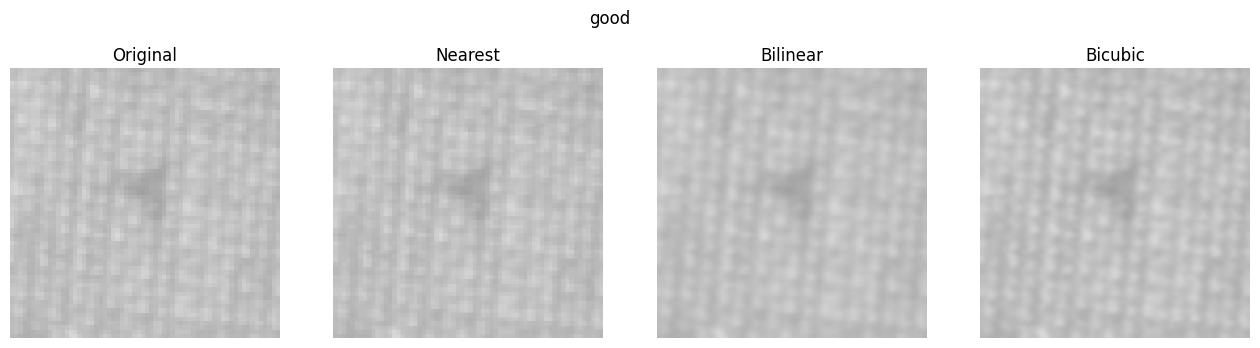

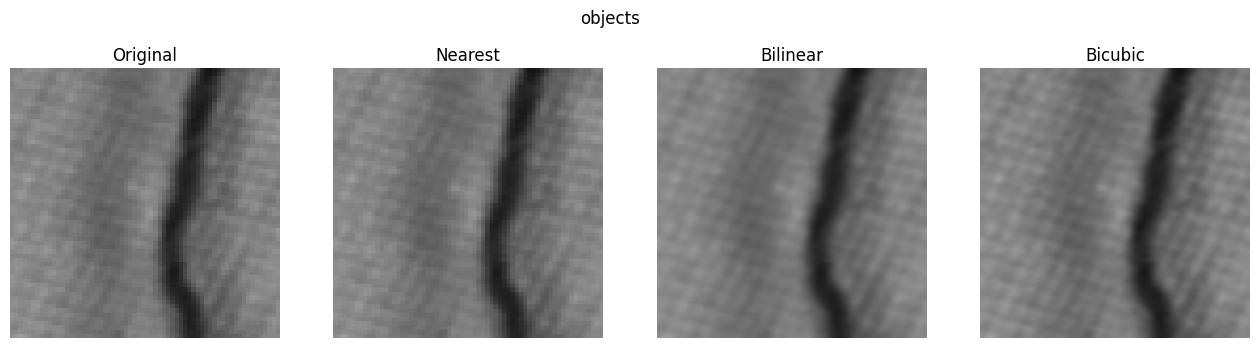

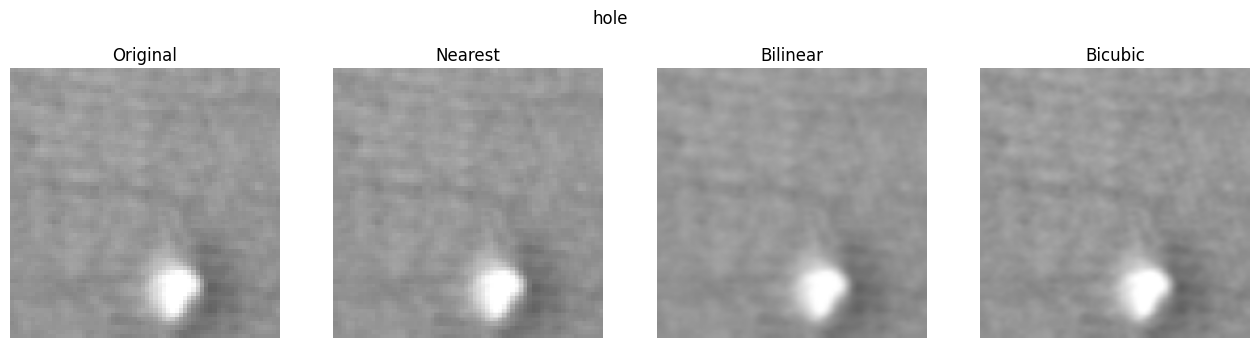

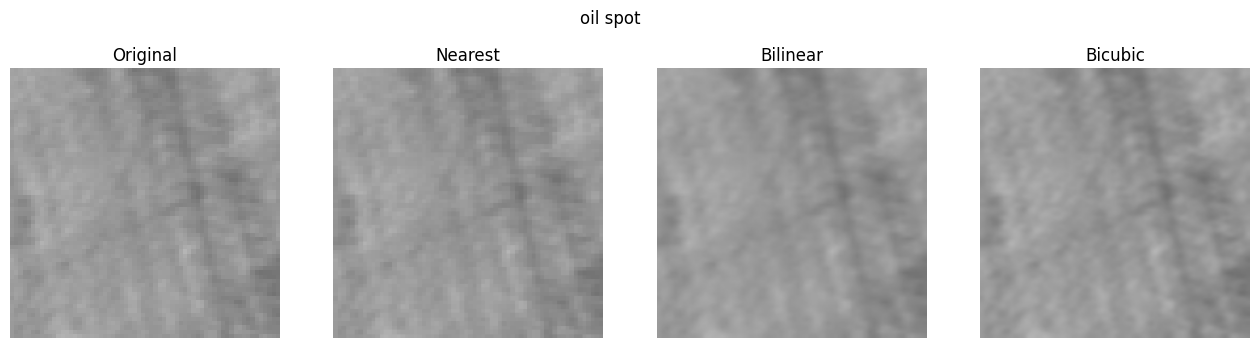

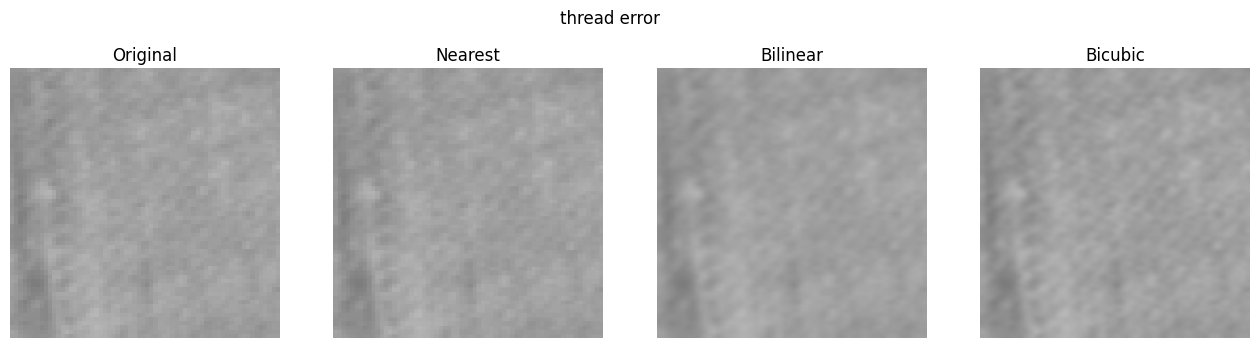

In [4]:
size = (224,224)

methods = {
    "Nearest": cv2.INTER_NEAREST,
    "Bilinear": cv2.INTER_LINEAR,
    "Bicubic": cv2.INTER_CUBIC
}

for class_name, img in images.items():

    fig, ax = plt.subplots(1,4, figsize=(16,4))

    ax[0].imshow(img)
    ax[0].set_title("Original")
    ax[0].axis("off")

    for i,(name,method) in enumerate(methods.items()):

        resized = cv2.resize(img, size, interpolation=method)

        ax[i+1].imshow(resized)
        ax[i+1].set_title(name)
        ax[i+1].axis("off")

    plt.suptitle(class_name)
    plt.show()

<h2>Sampling & Quantization</h2>

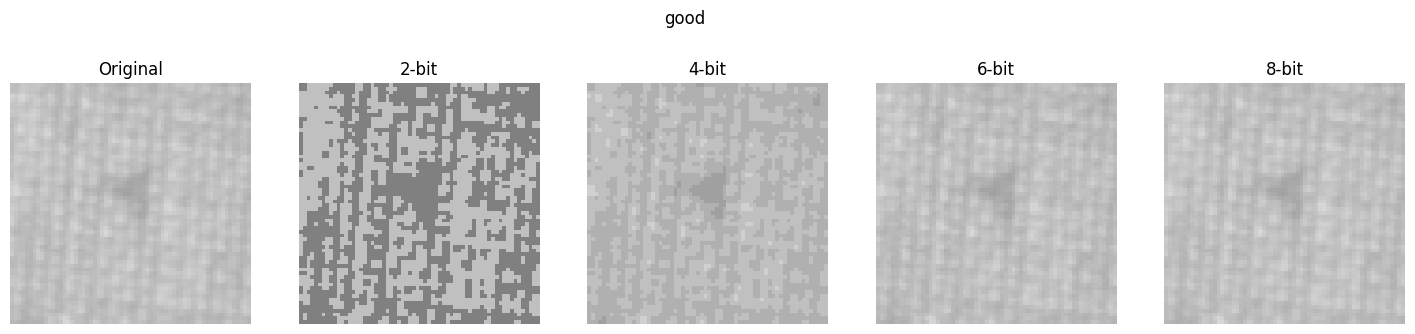

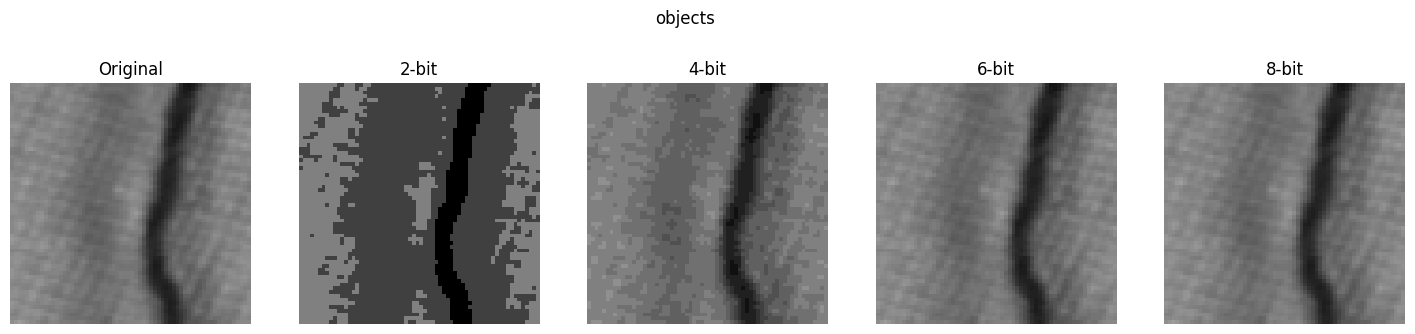

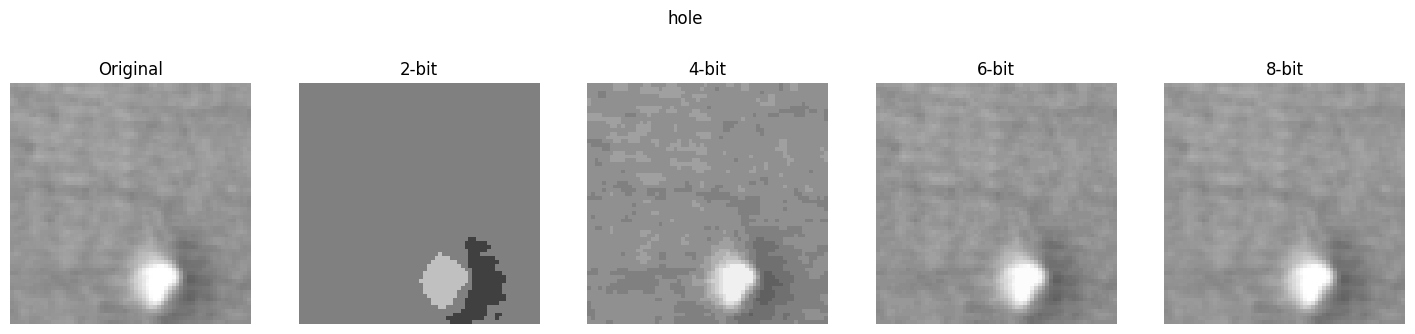

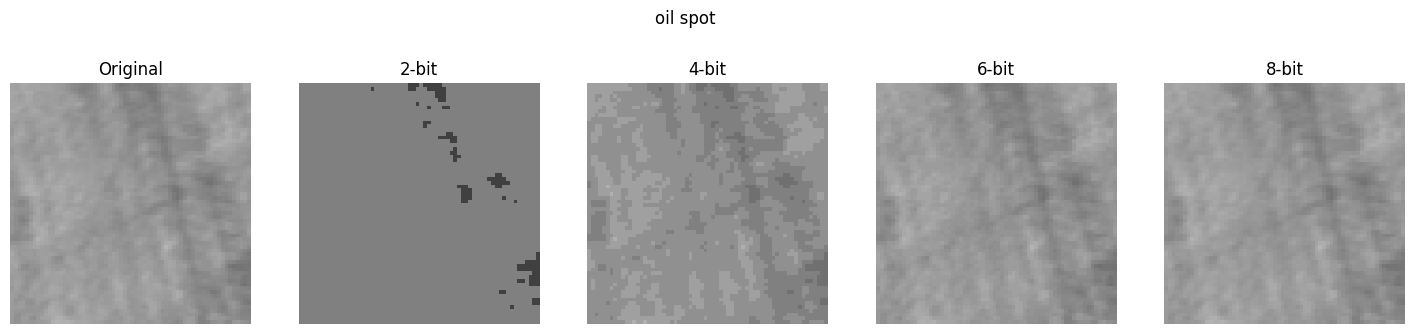

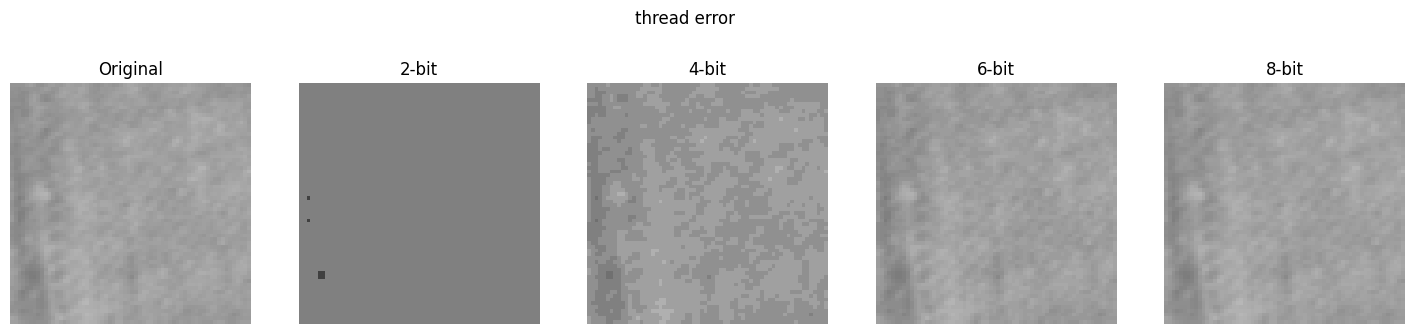

In [5]:
def quantize(image, bits):

    levels = 2**bits

    image = np.floor(image/(256/levels))

    image = image*(256/levels)

    return image.astype(np.uint8)


bit_levels = [2,4,6,8]

for class_name, img in images.items():

    fig, ax = plt.subplots(1,5, figsize=(18,4))

    ax[0].imshow(img)
    ax[0].set_title("Original")
    ax[0].axis("off")

    for i,b in enumerate(bit_levels):

        q = quantize(img,b)

        ax[i+1].imshow(q)
        ax[i+1].set_title(f"{b}-bit")
        ax[i+1].axis("off")

    plt.suptitle(class_name)
    plt.show()

8-bit is suitable and clear based in the results

In [6]:
# Use Bicubic interpolation (best visual quality) for further processing

processed_images = {}

for class_name, img in images.items():

    resized = cv2.resize(img, (224,224), interpolation=cv2.INTER_CUBIC)

    processed_images[class_name] = resized

print("Processing will continue using:")
print("- 224 × 224 images")
print("- Bicubic interpolation")
print("- 8-bit quantization")

Processing will continue using:
- 224 × 224 images
- Bicubic interpolation
- 8-bit quantization


<h2>Gamma Correction</h2>

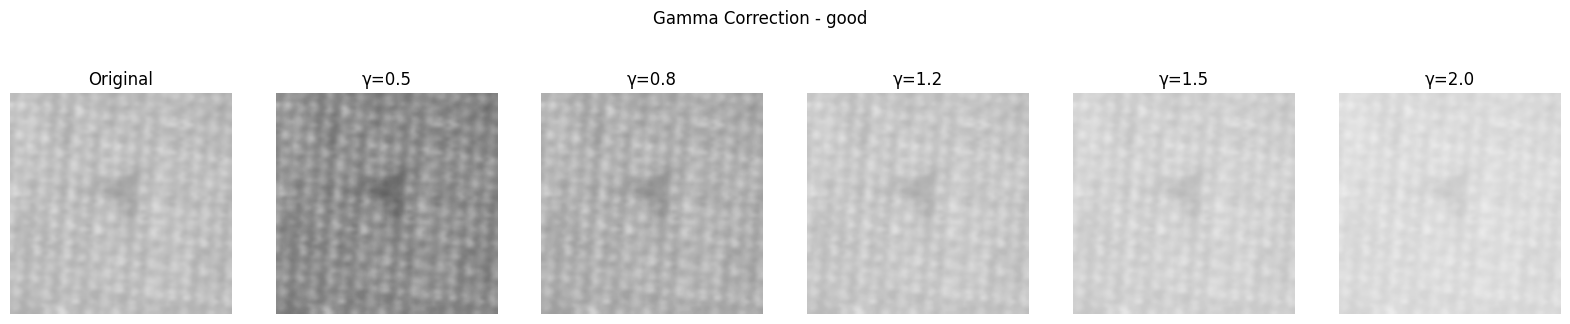

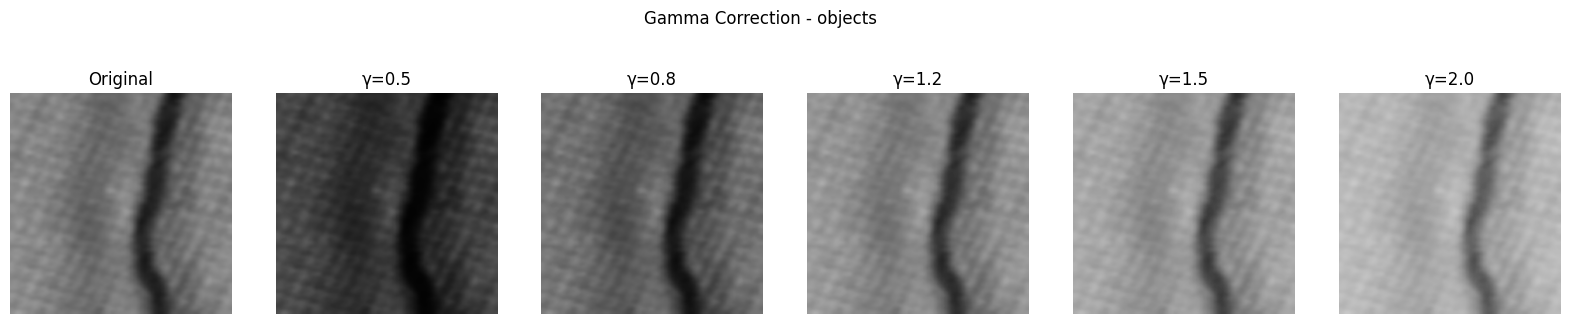

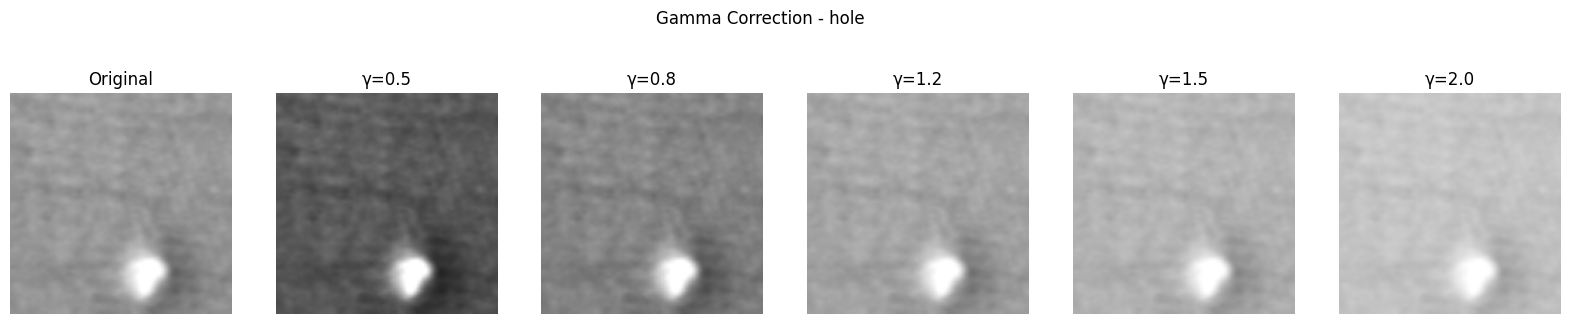

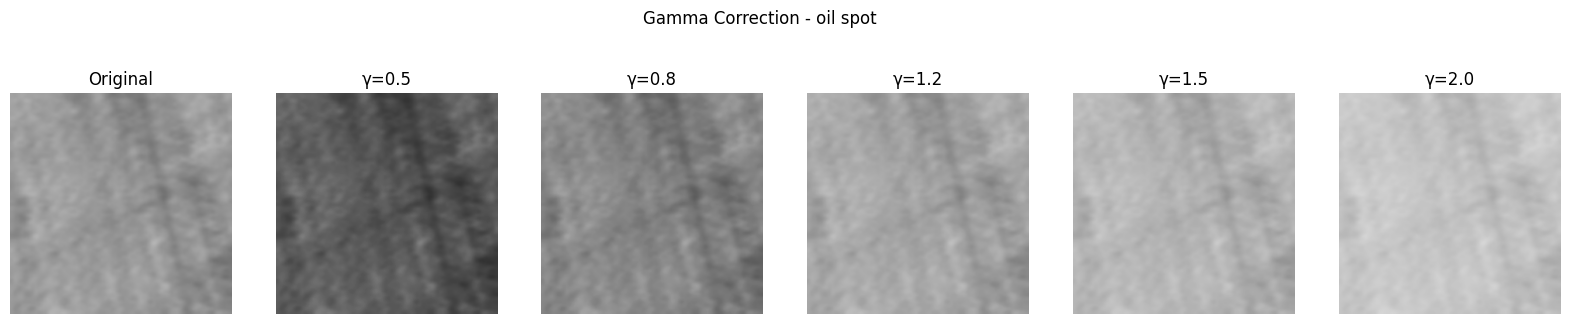

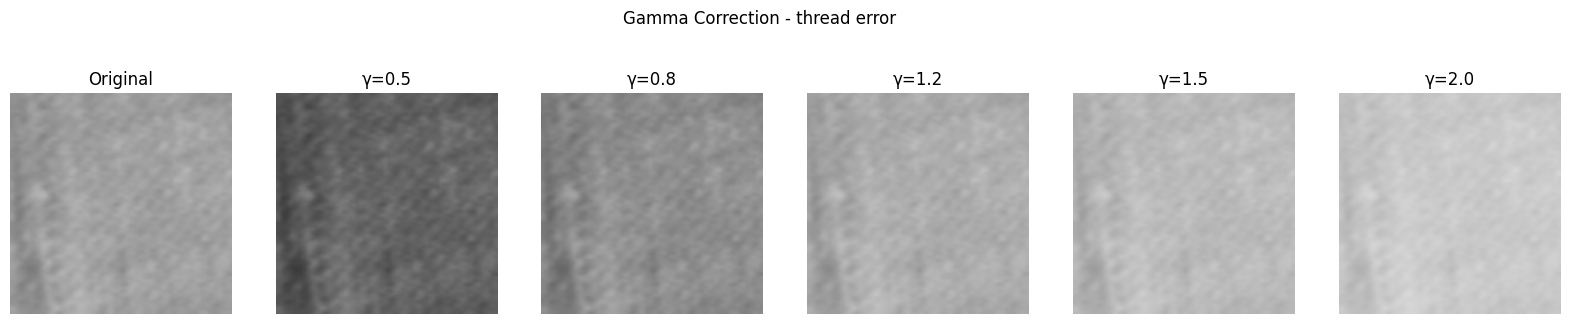

In [7]:
gamma_values = [0.5, 0.8, 1.2, 1.5, 2.0]

for class_name, img in processed_images.items():

    fig, ax = plt.subplots(1, 6, figsize=(20,4))

    ax[0].imshow(img)
    ax[0].set_title("Original")
    ax[0].axis("off")

    for i, gamma in enumerate(gamma_values):

        invGamma = 1/gamma

        table = np.array([
            ((j/255.0)**invGamma)*255
            for j in np.arange(256)
        ]).astype("uint8")

        corrected = cv2.LUT(img, table)

        ax[i+1].imshow(corrected)
        ax[i+1].set_title(f"γ={gamma}")
        ax[i+1].axis("off")

    plt.suptitle(f"Gamma Correction - {class_name}")
    plt.show()

<h2>Contrast Stretching (Min-Max)</h2>

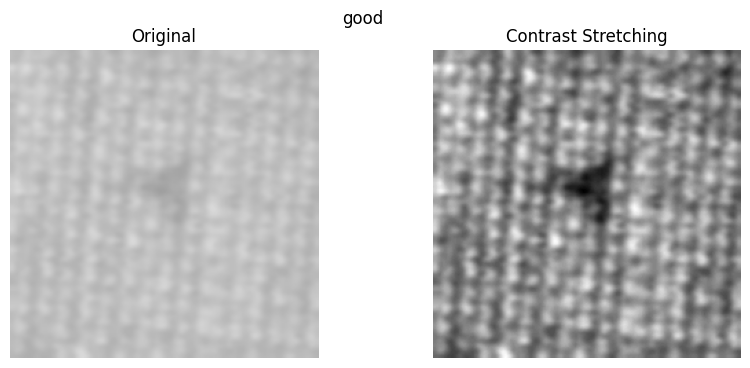

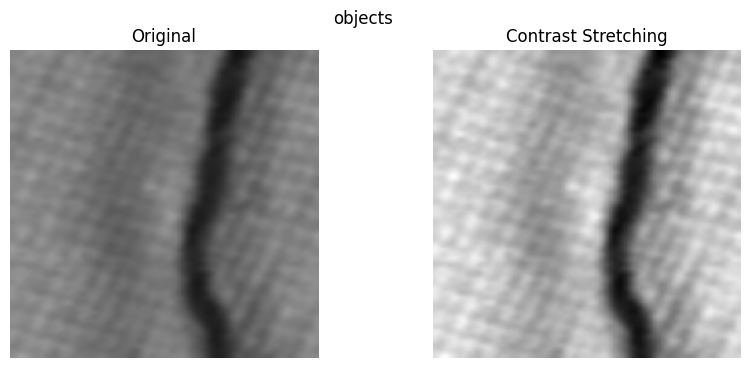

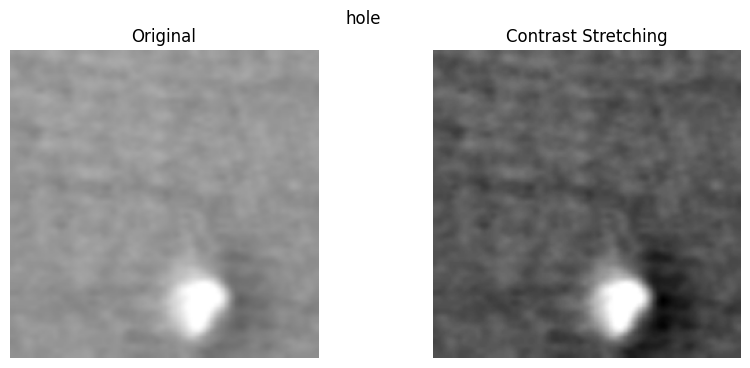

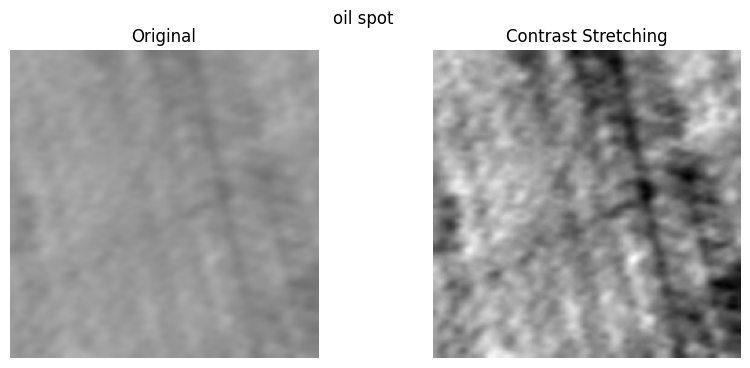

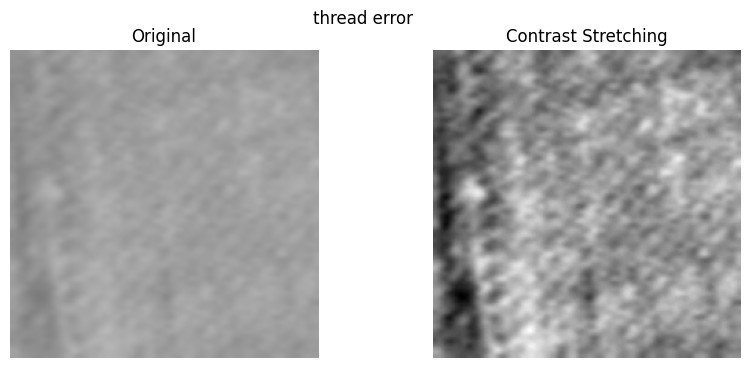

In [8]:
for class_name, img in processed_images.items():

    stretched = cv2.normalize(
        img,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    fig, ax = plt.subplots(1,2, figsize=(10,4))

    ax[0].imshow(img)
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(stretched)
    ax[1].set_title("Contrast Stretching")
    ax[1].axis("off")

    plt.suptitle(class_name)
    plt.show()

<h2>Mean Filter</h2>

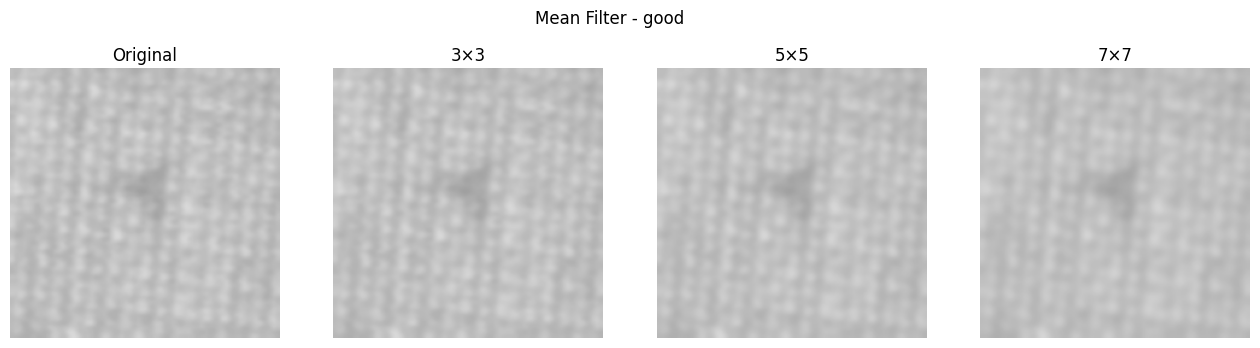

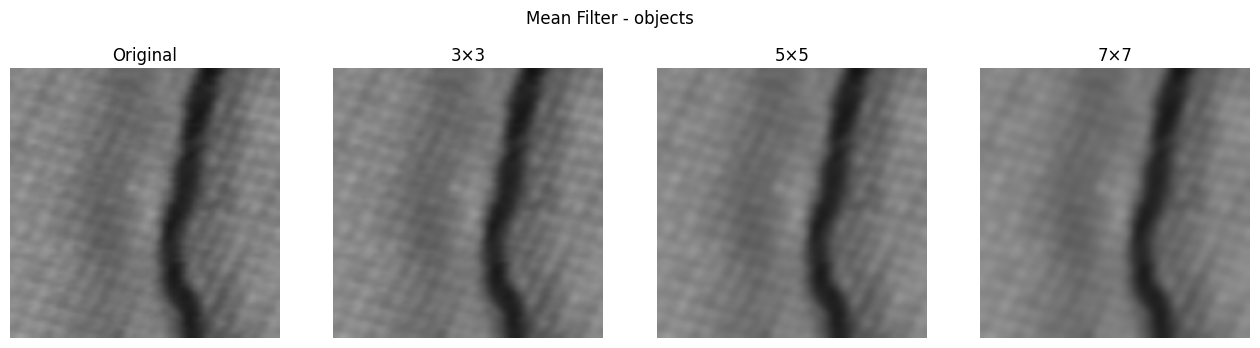

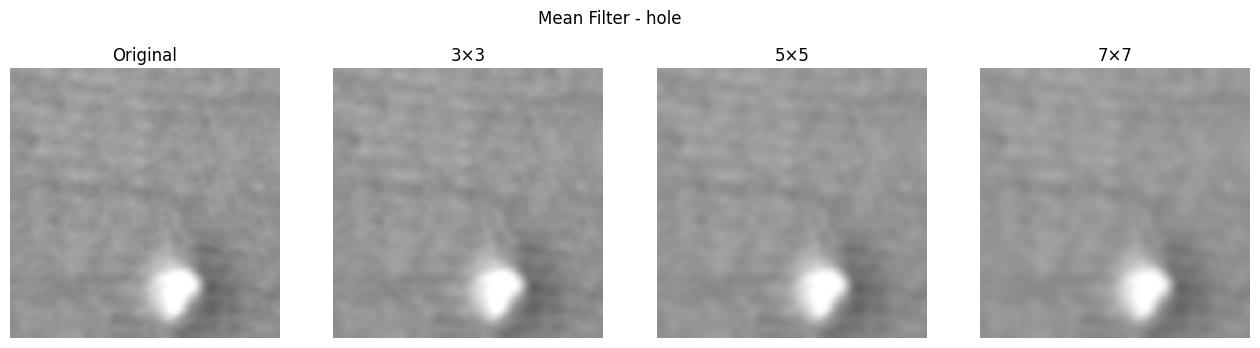

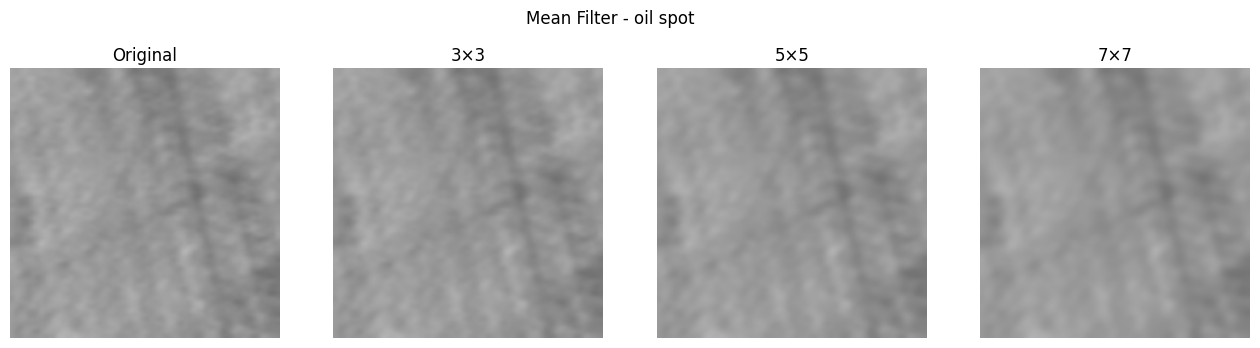

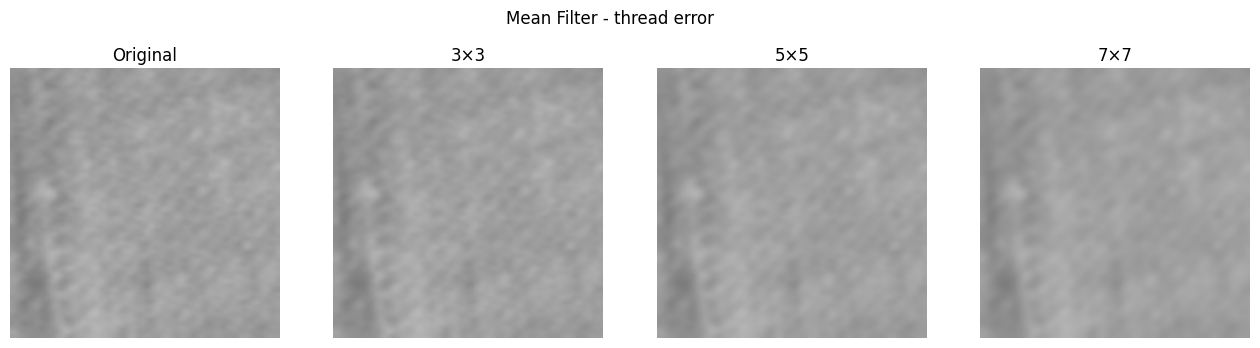

In [9]:
kernel_sizes = [3,5,7]

for class_name, img in processed_images.items():

    fig, ax = plt.subplots(1,4, figsize=(16,4))

    ax[0].imshow(img)
    ax[0].set_title("Original")
    ax[0].axis("off")

    for i, k in enumerate(kernel_sizes):

        filtered = cv2.blur(img, (k,k))

        ax[i+1].imshow(filtered)
        ax[i+1].set_title(f"{k}×{k}")
        ax[i+1].axis("off")

    plt.suptitle(f"Mean Filter - {class_name}")
    plt.show()

<h2>Gaussian Filter</h2>

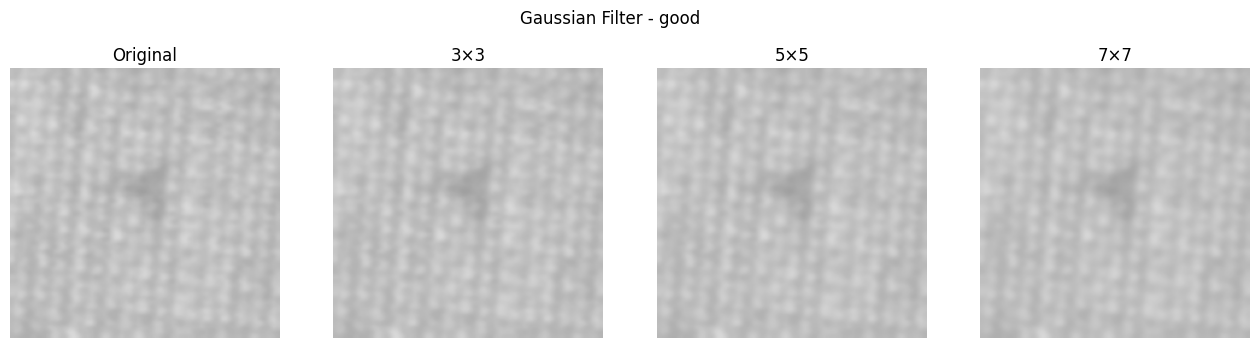

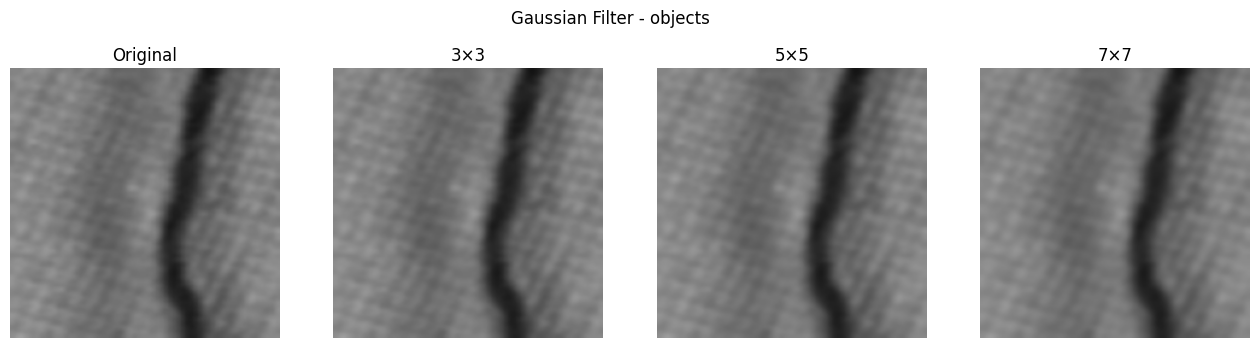

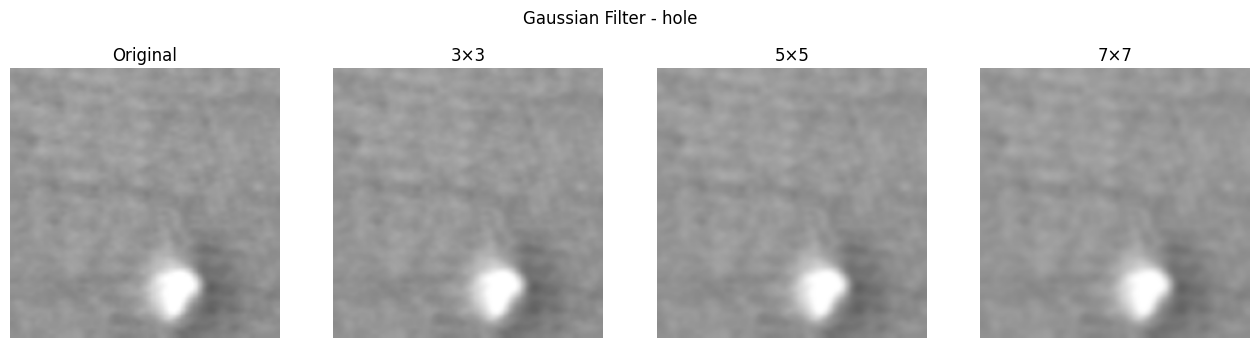

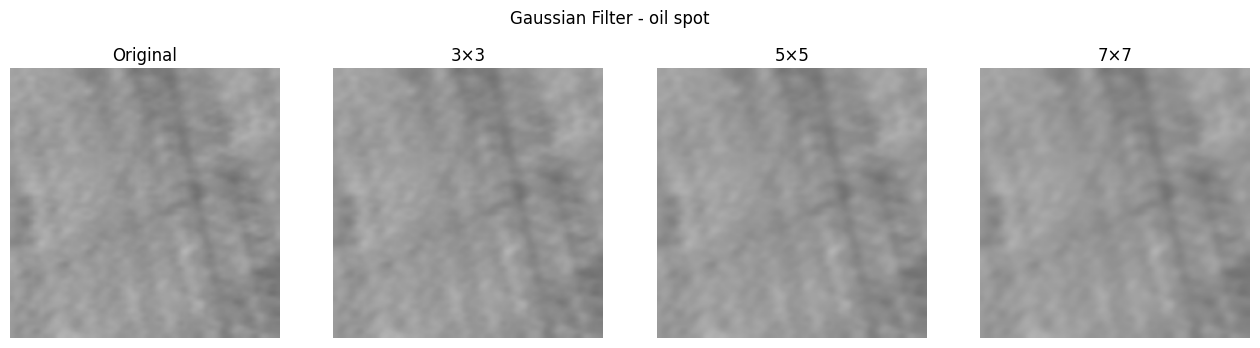

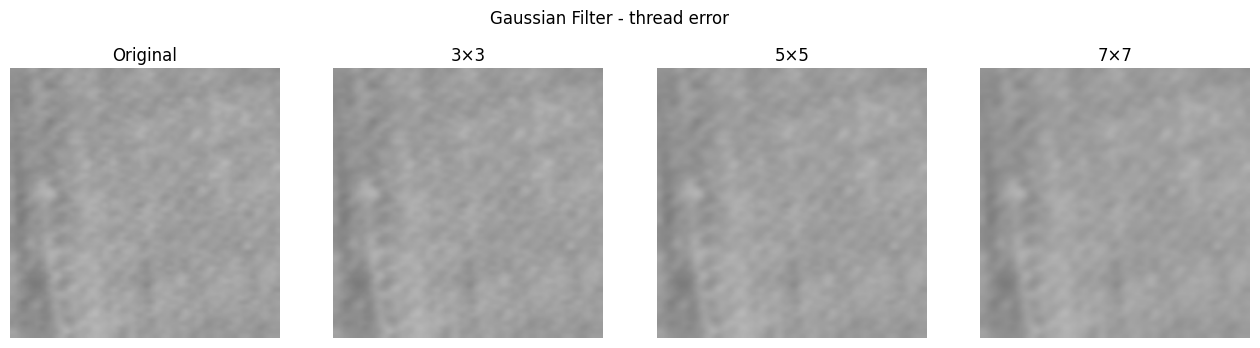

In [10]:
kernel_sizes = [3,5,7]

for class_name, img in processed_images.items():

    fig, ax = plt.subplots(1,4, figsize=(16,4))

    ax[0].imshow(img)
    ax[0].set_title("Original")
    ax[0].axis("off")

    for i, k in enumerate(kernel_sizes):

        filtered = cv2.GaussianBlur(img, (k,k), 0)

        ax[i+1].imshow(filtered)
        ax[i+1].set_title(f"{k}×{k}")
        ax[i+1].axis("off")

    plt.suptitle(f"Gaussian Filter - {class_name}")
    plt.show()

<h2>Mean Filter</h2>

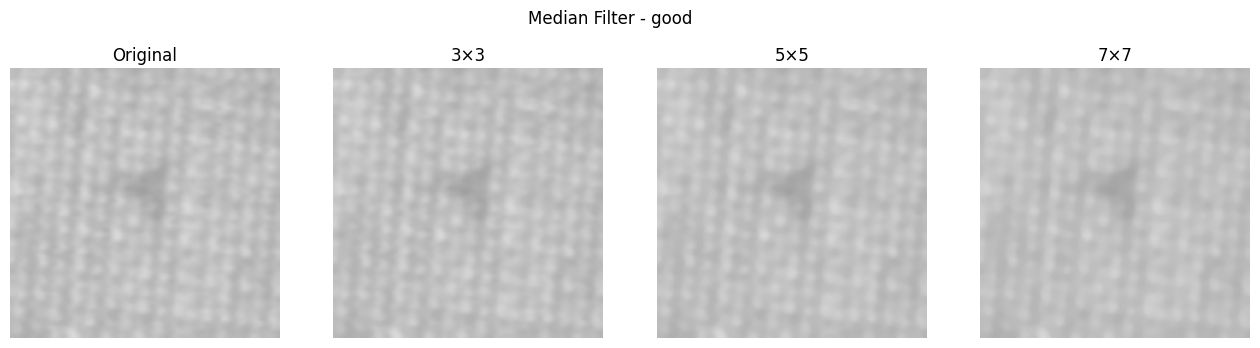

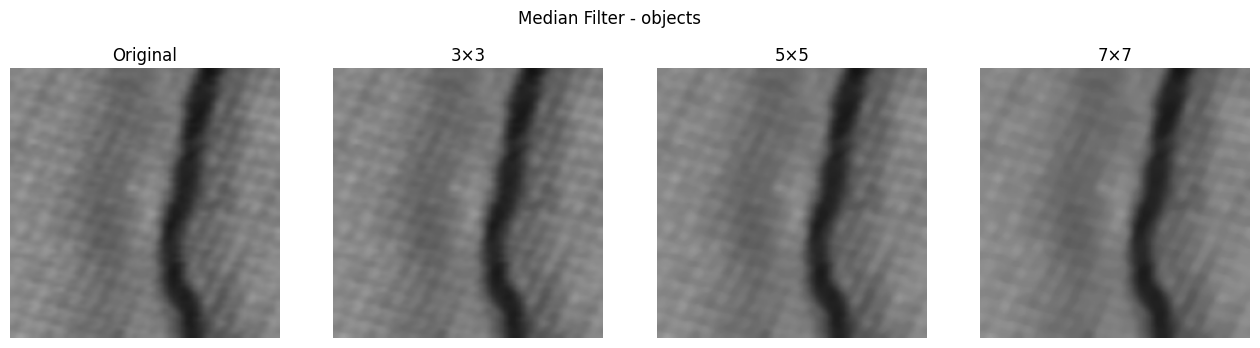

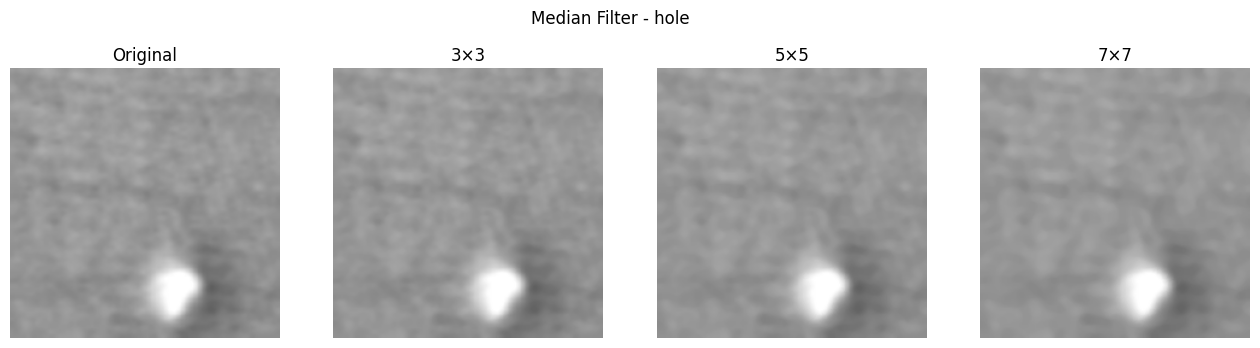

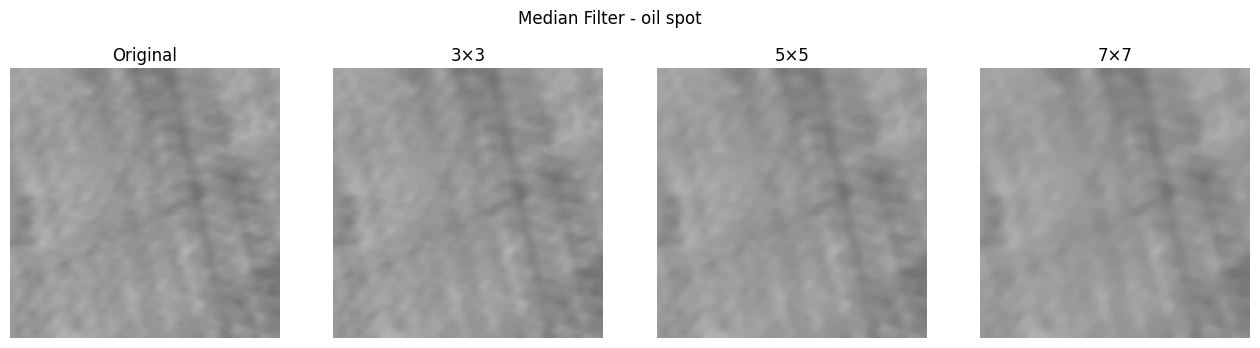

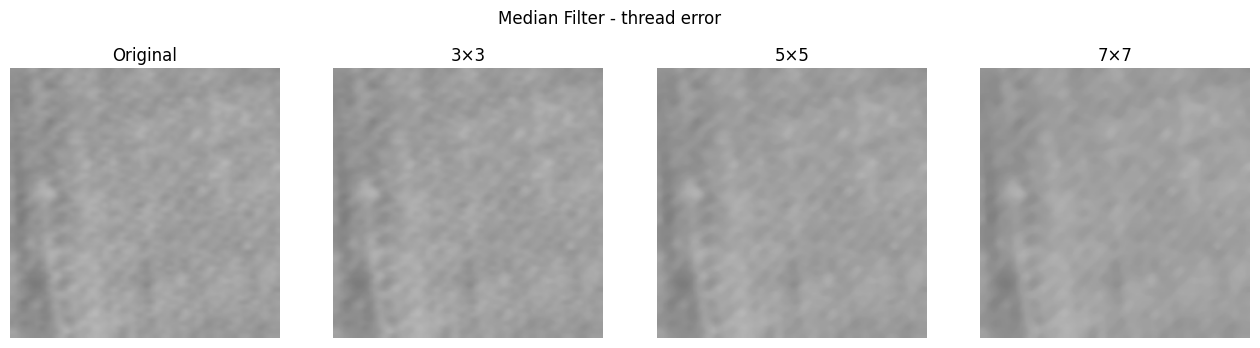

In [11]:
kernel_sizes = [3,5,7]

for class_name, img in processed_images.items():

    fig, ax = plt.subplots(1,4, figsize=(16,4))

    ax[0].imshow(img)
    ax[0].set_title("Original")
    ax[0].axis("off")

    for i, k in enumerate(kernel_sizes):

        filtered = cv2.medianBlur(img, k)

        ax[i+1].imshow(filtered)
        ax[i+1].set_title(f"{k}×{k}")
        ax[i+1].axis("off")

    plt.suptitle(f"Median Filter - {class_name}")
    plt.show()

Based on the results the suitable pipeline would be

<h2>Selected Image Enhancement Pipeline</h2>

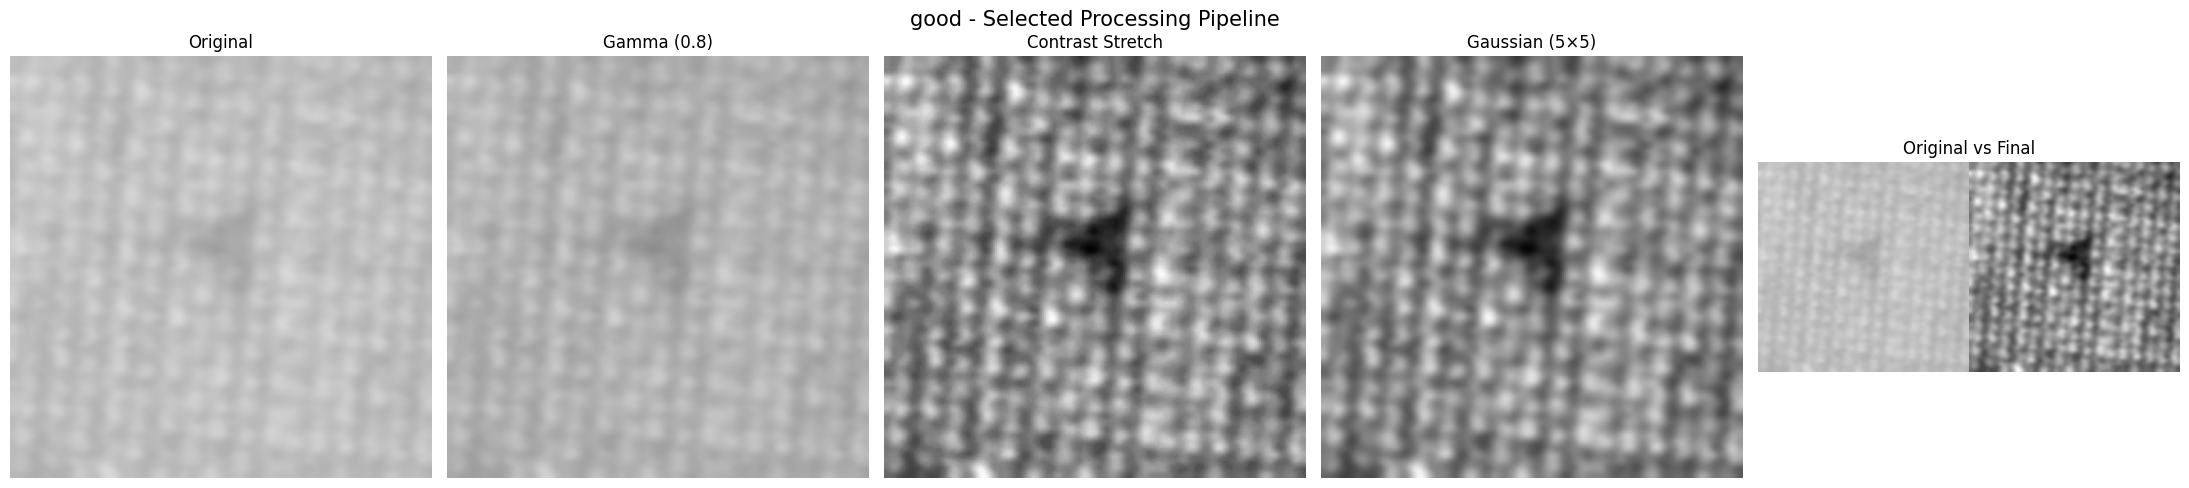

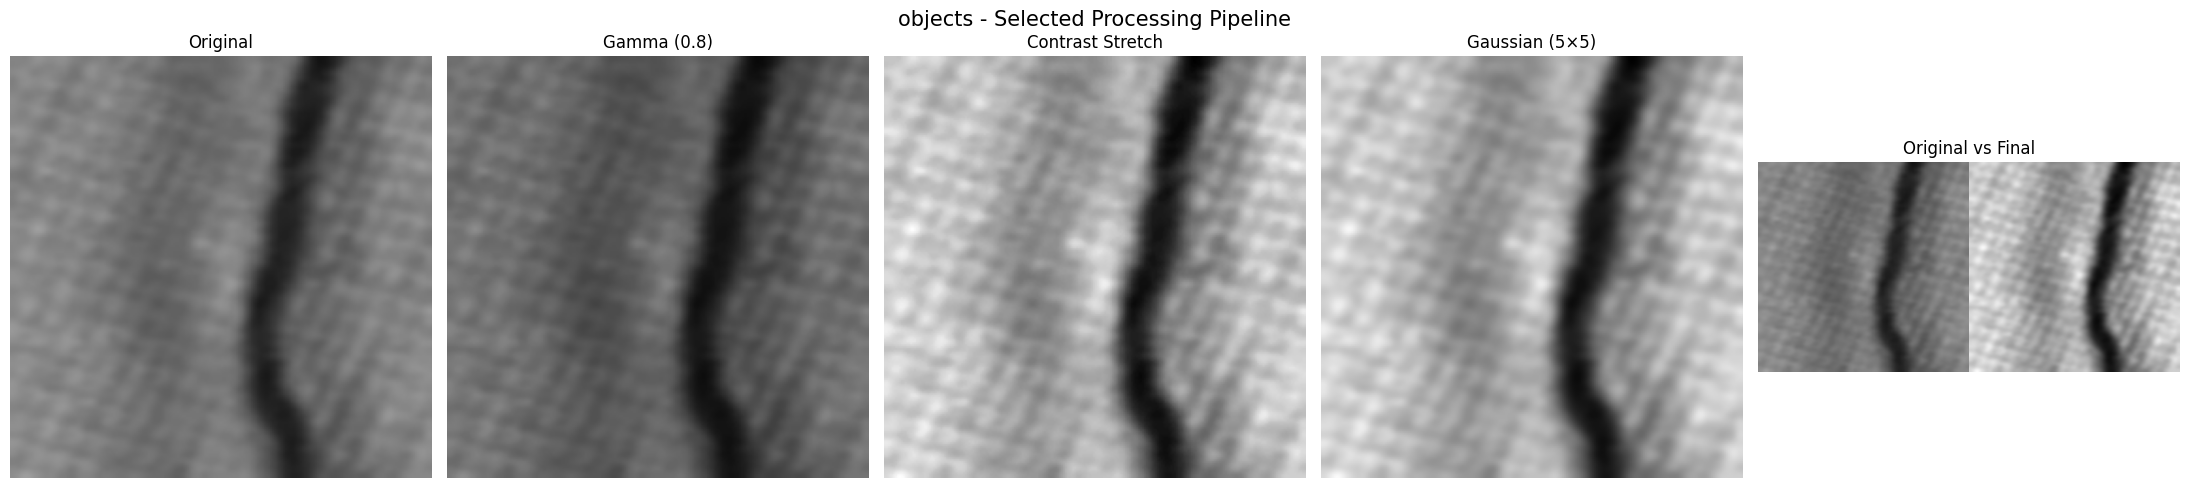

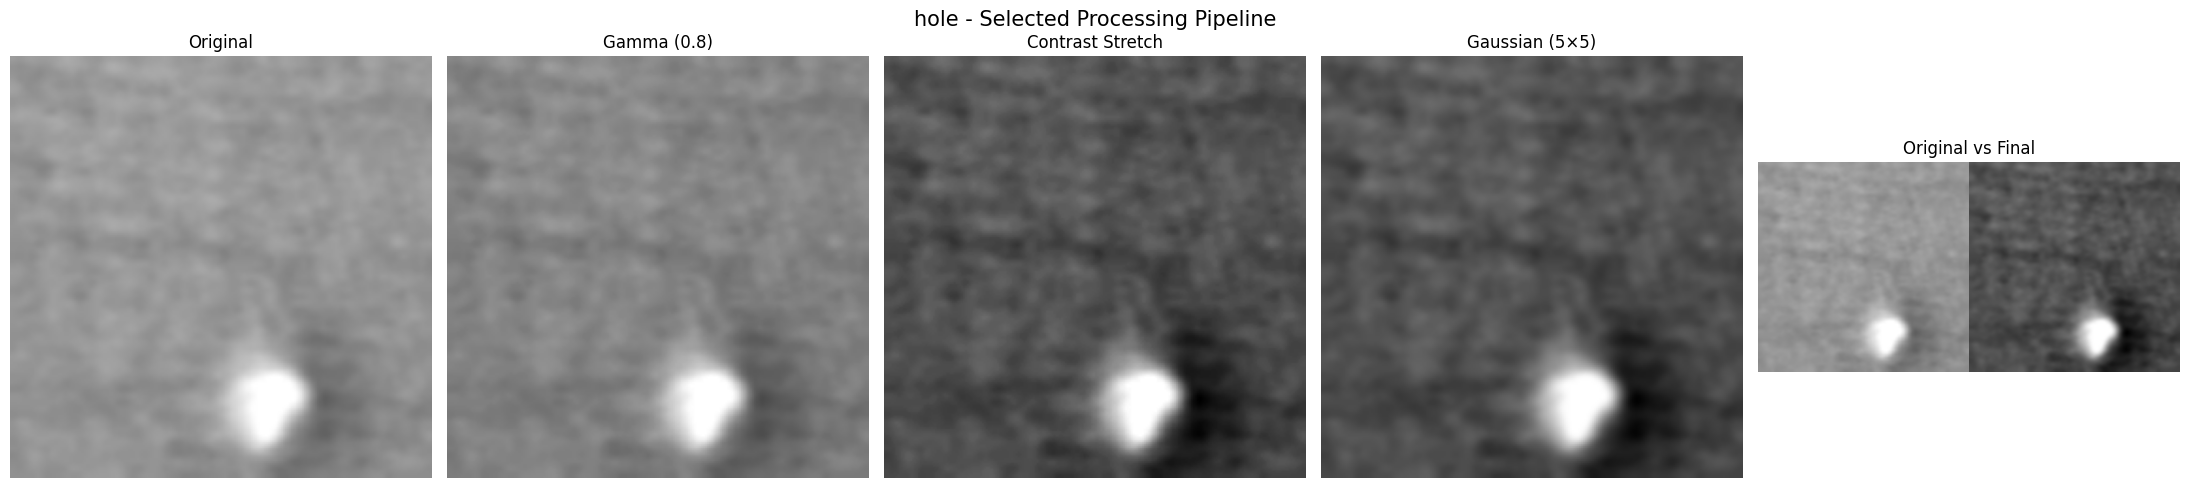

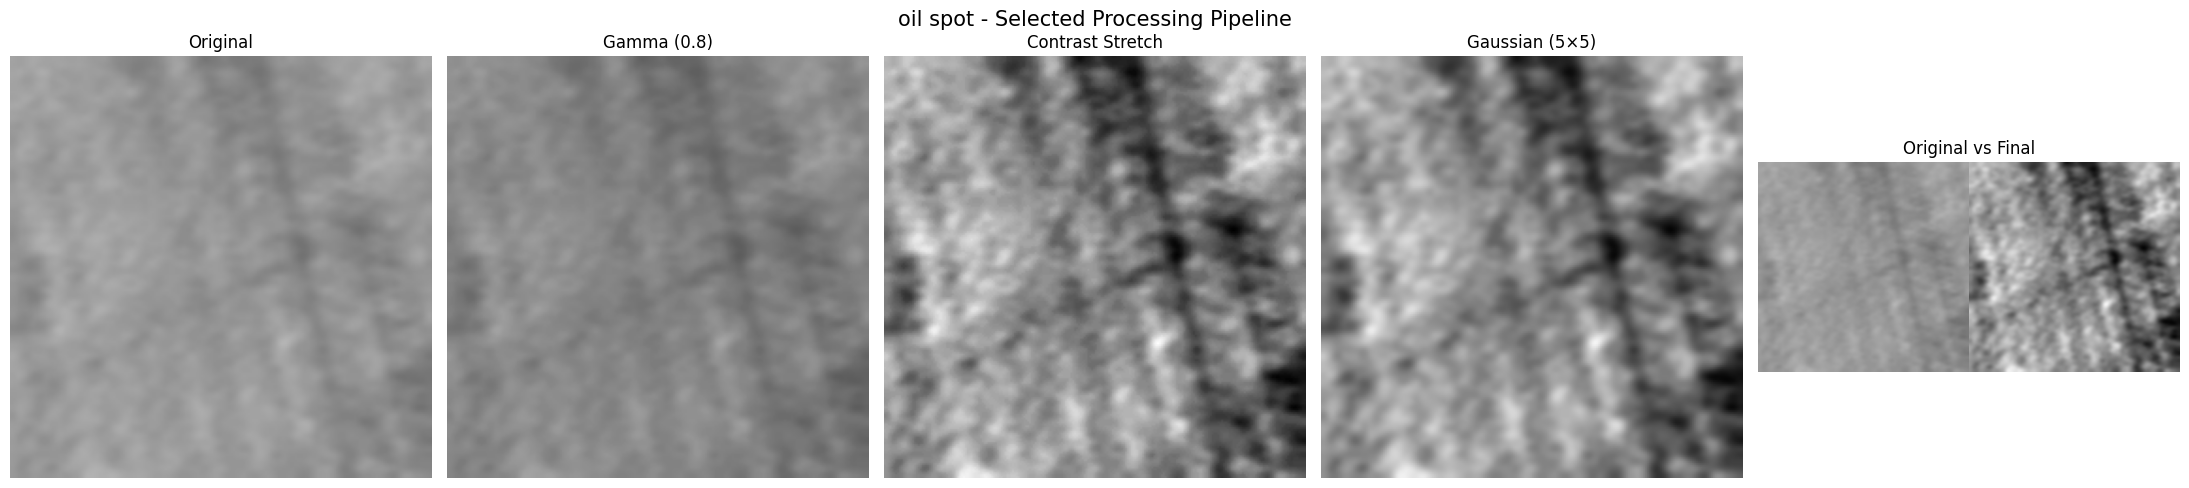

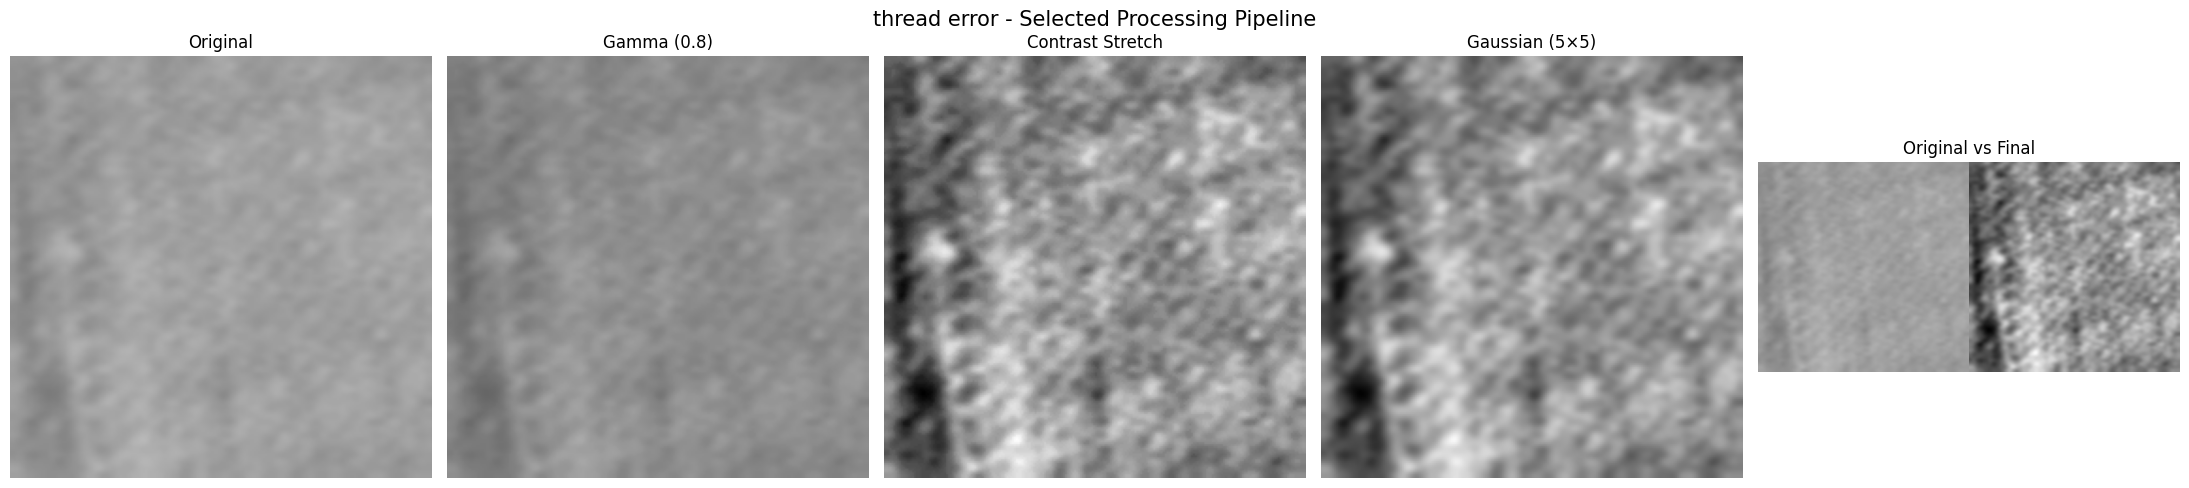

In [13]:
gamma = 0.8
kernel_size = 5

pipeline_images = {}

for class_name, img in processed_images.items():

    # -----------------------------
    # Step 1 : Gamma Correction
    # -----------------------------
    invGamma = 1.0 / gamma

    table = np.array([
        ((i / 255.0) ** invGamma) * 255
        for i in np.arange(256)
    ]).astype("uint8")

    gamma_img = cv2.LUT(img, table)

    # -----------------------------
    # Step 2 : Contrast Stretching
    # -----------------------------
    contrast_img = cv2.normalize(
        gamma_img,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    # -----------------------------
    # Step 3 : Gaussian Filter
    # -----------------------------
    final_img = cv2.GaussianBlur(
        contrast_img,
        (kernel_size, kernel_size),
        0
    )

    pipeline_images[class_name] = final_img

    # Display comparison
    fig, ax = plt.subplots(1,5, figsize=(22,5))

    ax[0].imshow(img)
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(gamma_img)
    ax[1].set_title("Gamma (0.8)")
    ax[1].axis("off")

    ax[2].imshow(contrast_img)
    ax[2].set_title("Contrast Stretch")
    ax[2].axis("off")

    ax[3].imshow(final_img)
    ax[3].set_title("Gaussian (5×5)")
    ax[3].axis("off")

    ax[4].imshow(np.hstack((img, final_img)))
    ax[4].set_title("Original vs Final")
    ax[4].axis("off")

    plt.suptitle(f"{class_name} - Selected Processing Pipeline", fontsize=15)
    plt.tight_layout()
    plt.show()

<h2>Final Comparison of All Classes</h2>

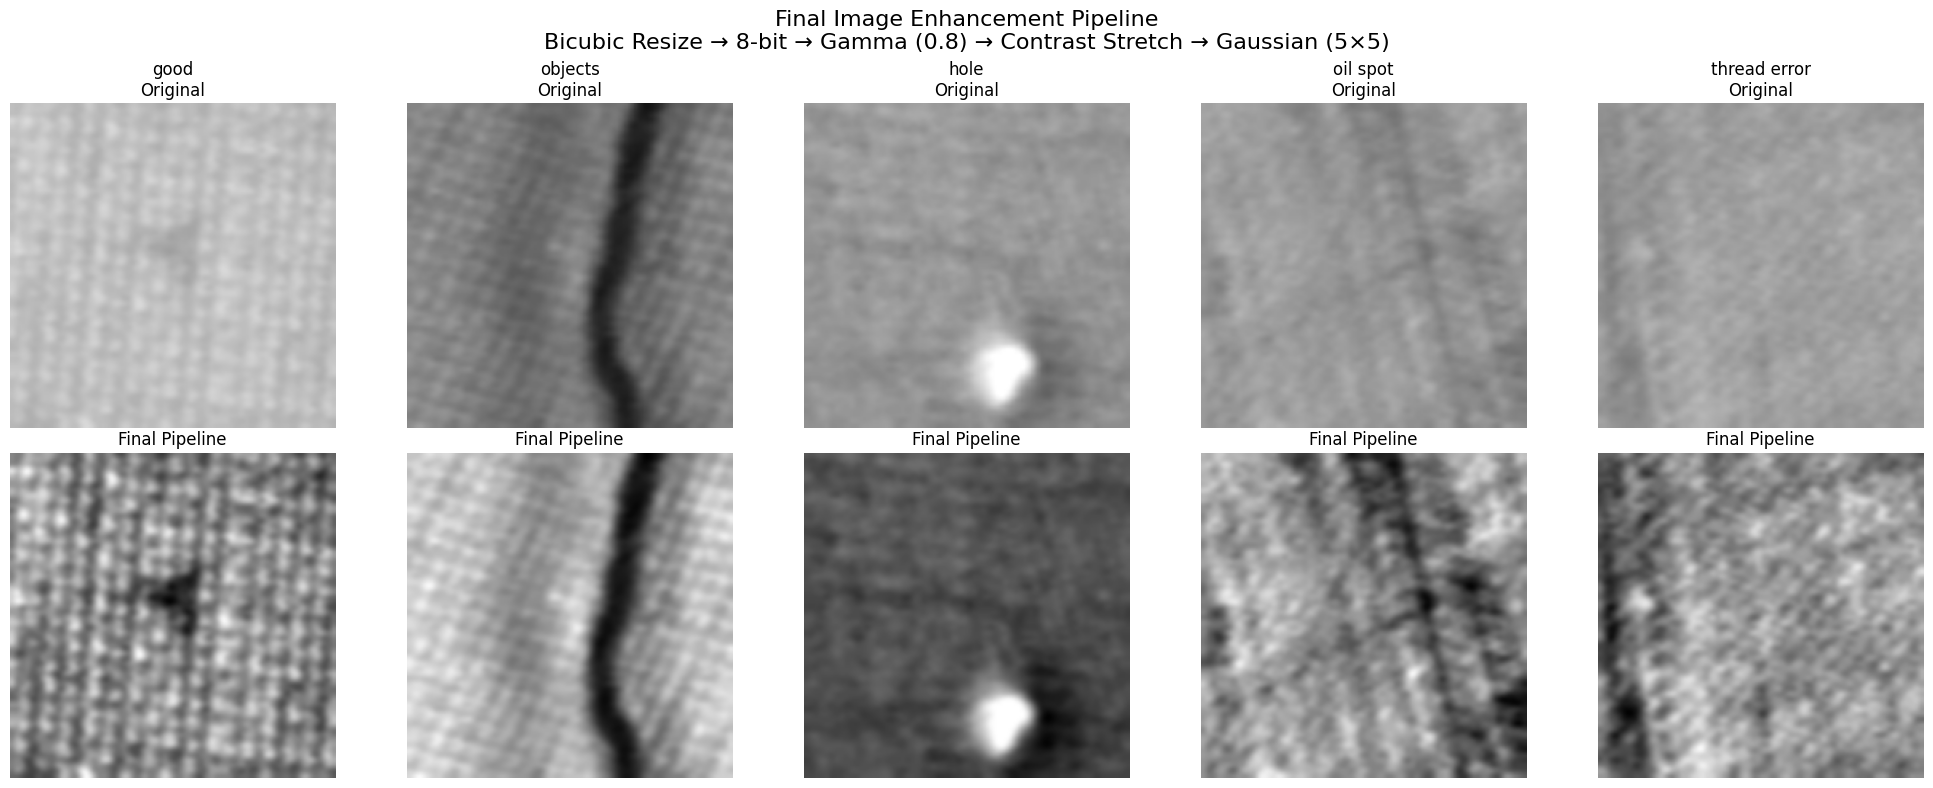

In [14]:
fig, ax = plt.subplots(2, len(pipeline_images), figsize=(20,8))

for i, (class_name, final_img) in enumerate(pipeline_images.items()):

    ax[0,i].imshow(processed_images[class_name])
    ax[0,i].set_title(f"{class_name}\nOriginal")
    ax[0,i].axis("off")

    ax[1,i].imshow(final_img)
    ax[1,i].set_title("Final Pipeline")
    ax[1,i].axis("off")

plt.suptitle(
    "Final Image Enhancement Pipeline\n"
    "Bicubic Resize → 8-bit → Gamma (0.8) → Contrast Stretch → Gaussian (5×5)",
    fontsize=16
)

plt.tight_layout()
plt.show()

<h2>Other Candidate Pipelines</h2>

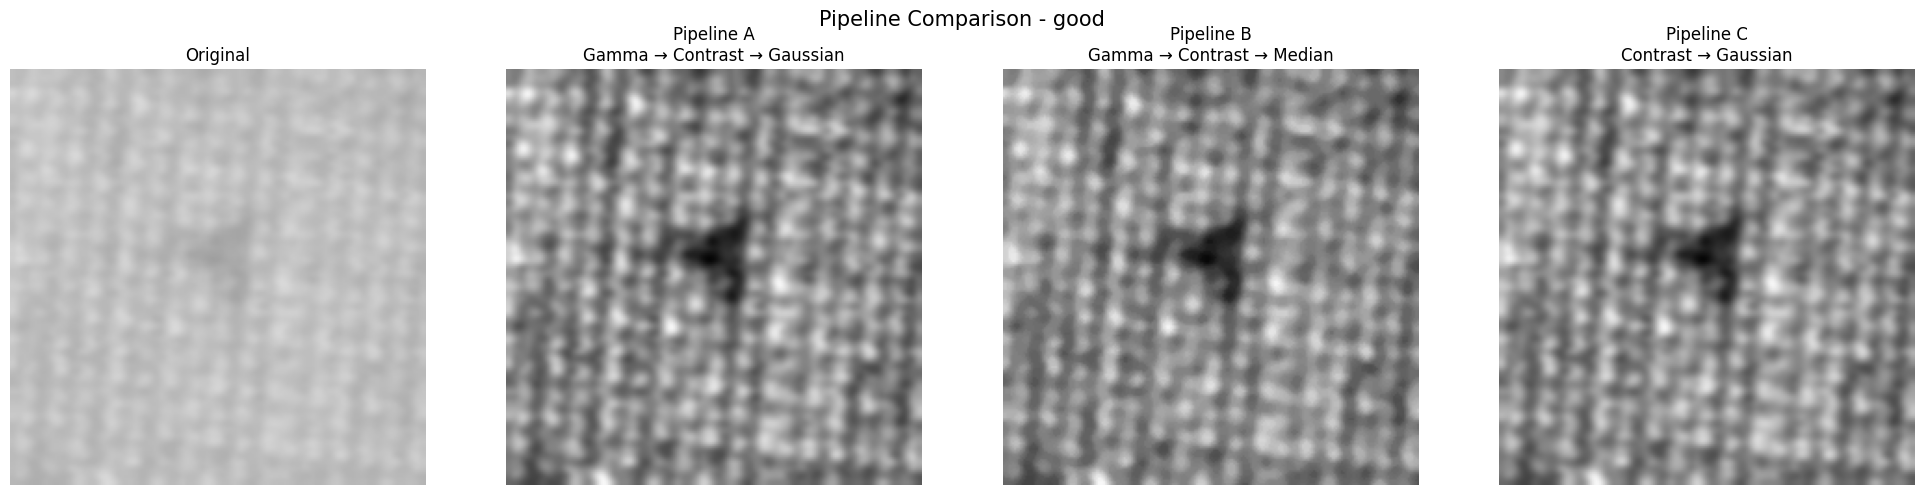

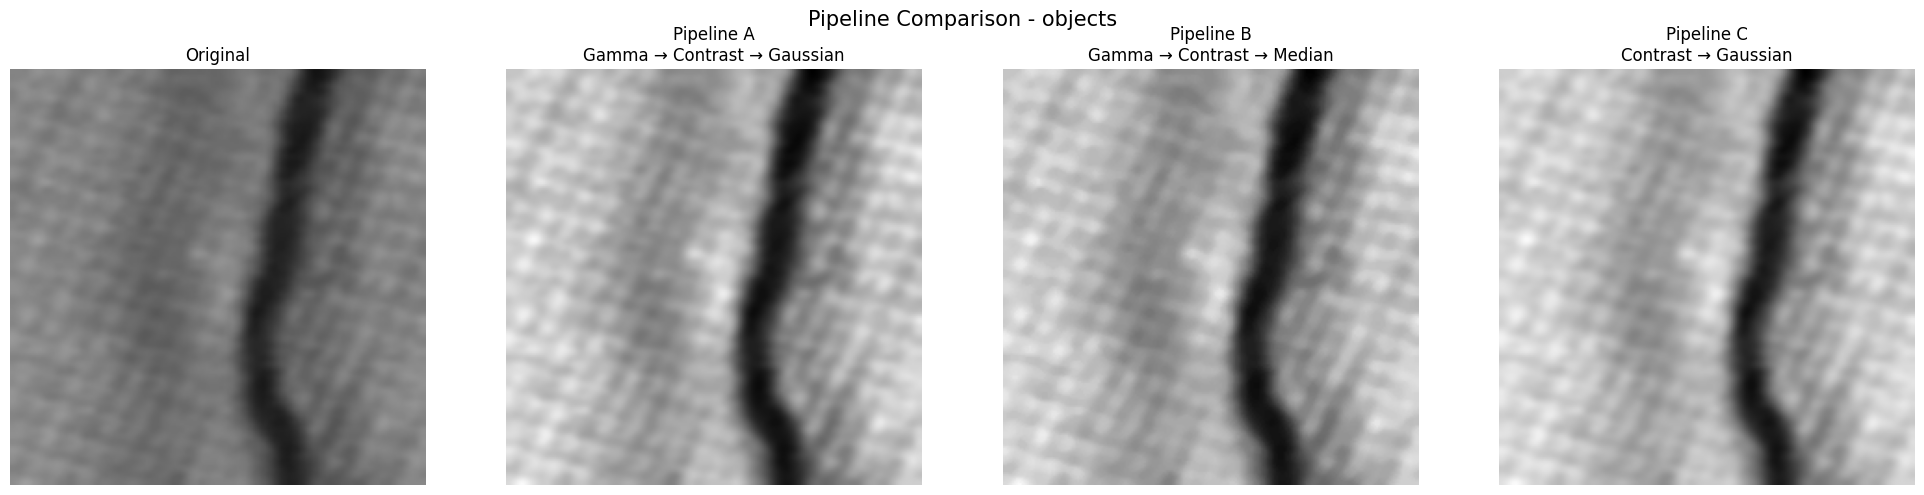

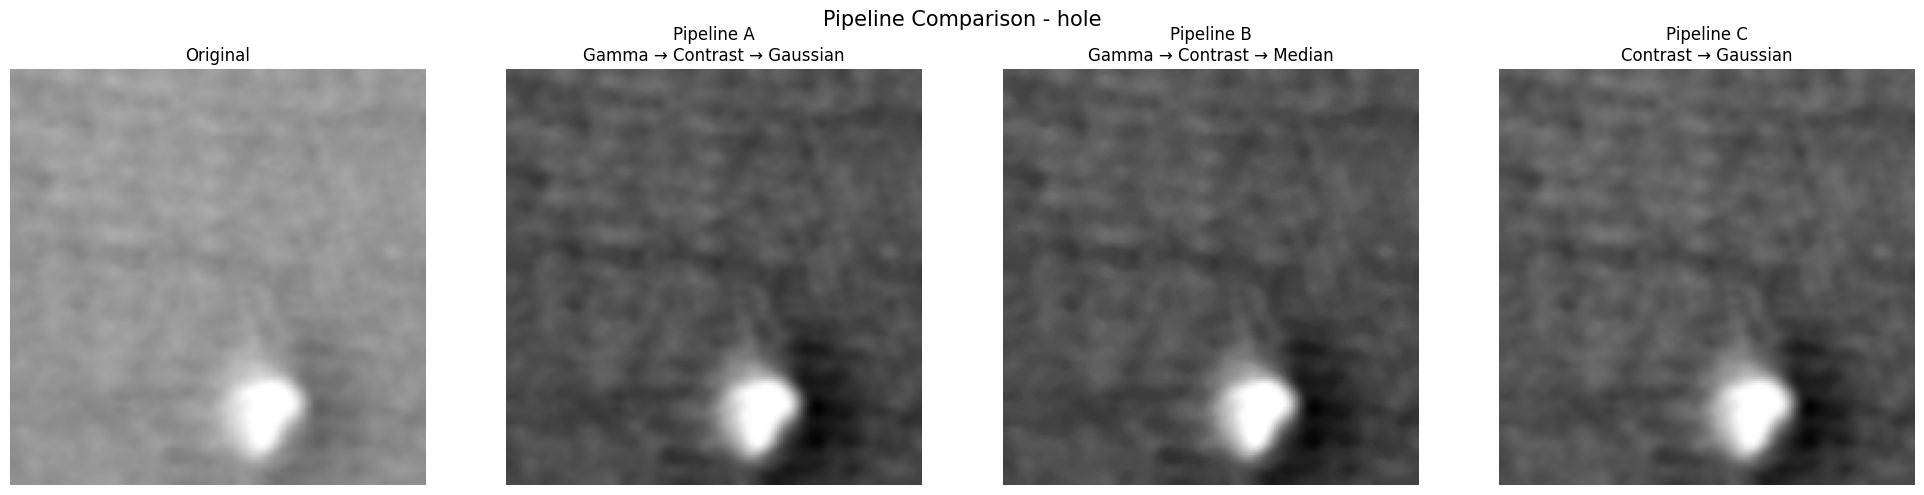

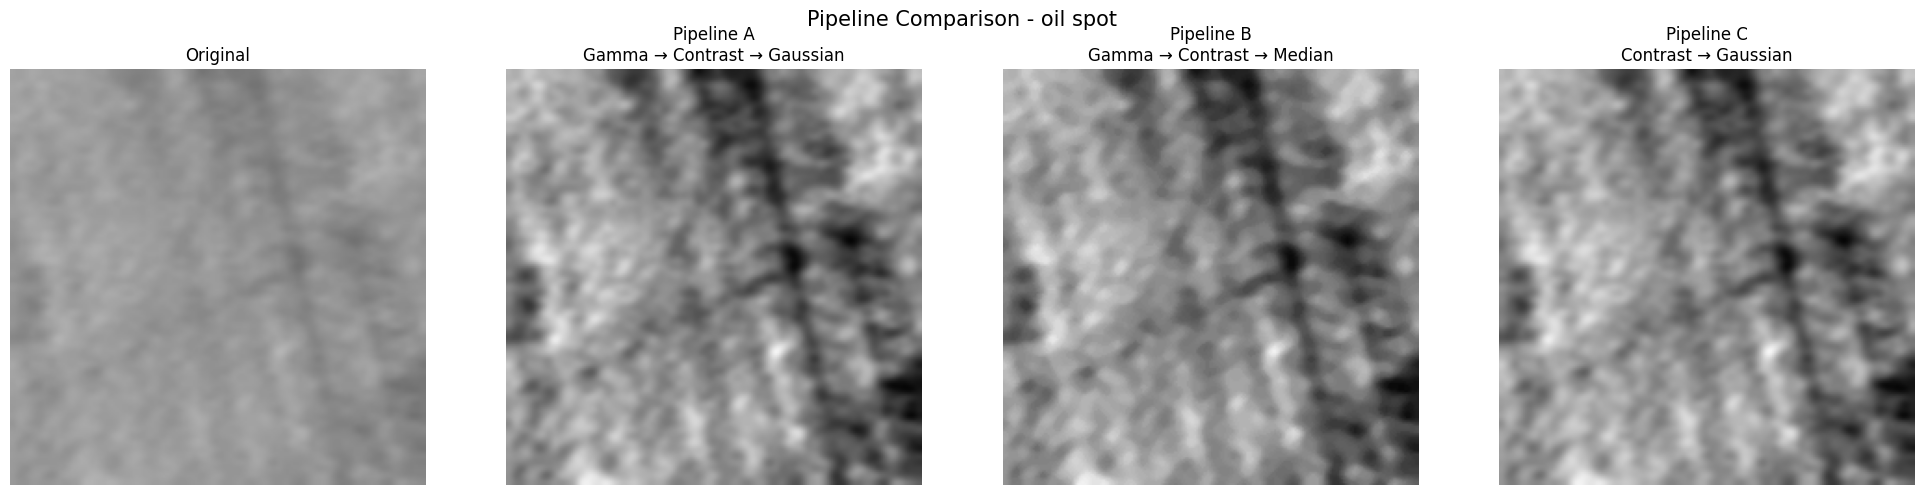

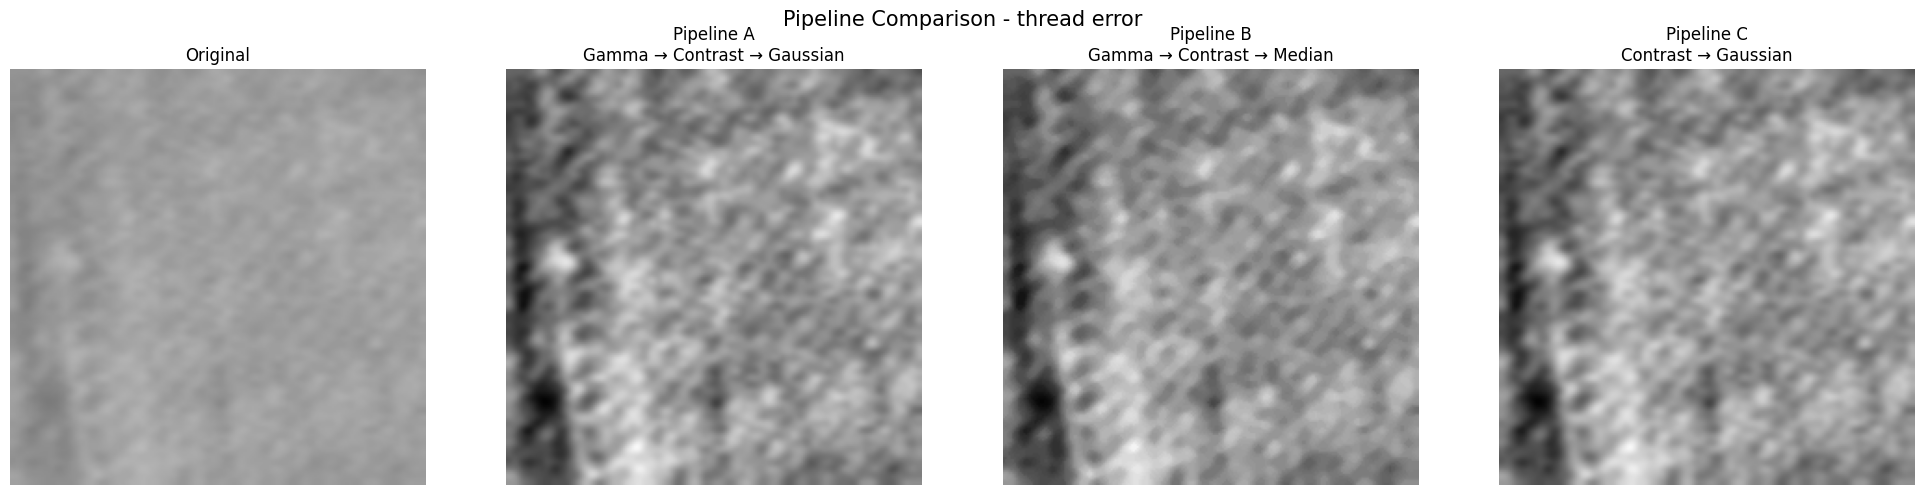

In [15]:
# Candidate Pipelines
# Pipeline A : Gamma (0.8) → Contrast Stretching → Gaussian (5x5)
# Pipeline B : Gamma (0.8) → Contrast Stretching → Median (5x5)
# Pipeline C : Contrast Stretching → Gaussian (5x5)

gamma = 0.8

for class_name, img in processed_images.items():

    # ---------- Pipeline A ----------
    table = np.array([
        ((i / 255.0) ** (1/gamma)) * 255
        for i in np.arange(256)
    ]).astype("uint8")

    gamma_img = cv2.LUT(img, table)

    contrast_a = cv2.normalize(
        gamma_img,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    pipeline_a = cv2.GaussianBlur(
        contrast_a,
        (5,5),
        0
    )

    # ---------- Pipeline B ----------
    contrast_b = cv2.normalize(
        gamma_img,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    pipeline_b = cv2.medianBlur(
        contrast_b,
        5
    )

    # ---------- Pipeline C ----------
    contrast_c = cv2.normalize(
        img,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    pipeline_c = cv2.GaussianBlur(
        contrast_c,
        (5,5),
        0
    )

    # ---------- Display ----------
    fig, ax = plt.subplots(1,4, figsize=(20,5))

    ax[0].imshow(img)
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(pipeline_a)
    ax[1].set_title("Pipeline A\nGamma → Contrast → Gaussian")
    ax[1].axis("off")

    ax[2].imshow(pipeline_b)
    ax[2].set_title("Pipeline B\nGamma → Contrast → Median")
    ax[2].axis("off")

    ax[3].imshow(pipeline_c)
    ax[3].set_title("Pipeline C\nContrast → Gaussian")
    ax[3].axis("off")

    plt.suptitle(f"Pipeline Comparison - {class_name}", fontsize=15)
    plt.tight_layout()
    plt.show()